1. Các chỉ báo kỹ thuật (Indicators)

Keltner Channel (KC): Chu kỳ 20.

RSI: Chu kỳ 14.

ATR: Sử dụng rất nhiều chu kỳ khác nhau:

ATR(23): Tính khoảng cách đặt lệnh (Entry Buffer).

ATR(20): Tính Stop Loss.

ATR(25): Tính Profit Target.

ATR(150): Tính Trailing Stop

Highest/Lowest Close: Chu kỳ 10 (Biến PeriodParam).

2. Logic Vào Lệnh (Entry Signal)

Chiến lược này tìm kiếm sự bùng nổ ngay từ khi mở nến.

Điều kiện MUA (Long Setup):

Giá Mở cửa (Open) của nến hiện tại phải nằm trên dải trên Keltner (Deviation 2.0).

Ý nghĩa: Giá mở cửa nhảy vọt (Gap up) hoặc đẩy rất mạnh ra ngoài biên độ bình thường.

RSI đang tăng: RSI(cách đây 3 nến) < RSI(cách đây 2 nến).

Điều kiện BÁN (Short Setup):

Giá Mở cửa (Open) nằm dưới dải dưới Keltner (Deviation 2.0).

RSI đang giảm: RSI(cách đây 3 nến) > RSI(cách đây 2 nến).
3. Điểm Đặt Lệnh (Execution)


Đây là chiến lược đặt lệnh chờ (Stop Order) dựa trên dữ liệu quá khứ cách đây 3 nến.

Buy Stop:

Giá = Highest(Close, 10) [lùi lại 3 nến] + 2.4 * ATR(23) [lùi lại 3 nến].

Sell Stop:

Giá = Lowest(Close, 10) [lùi lại 3 nến] - 2.4 * ATR(23) [lùi lại 3 nến].

Hủy lệnh (Expiration): Sau 5 cây nến.

4. Thoát Lệnh (Exit)

Stop Loss: 2.2 * ATR(20).

Profit Target: 4.3 * ATR(25) (R:R rất cao, gần 1:2).

Trailing Stop: 3.0 * ATR(150). (Dùng ATR dài hạn để Trailing rất lỏng, nuôi sóng lớn).

Time Exit: Thoát sau 14 cây nến (StrategyQuant thường dùng Time Exit để tránh chôn vốn).


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.3/240.3 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 104.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 16.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.1 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.2.6 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.1 which is incom

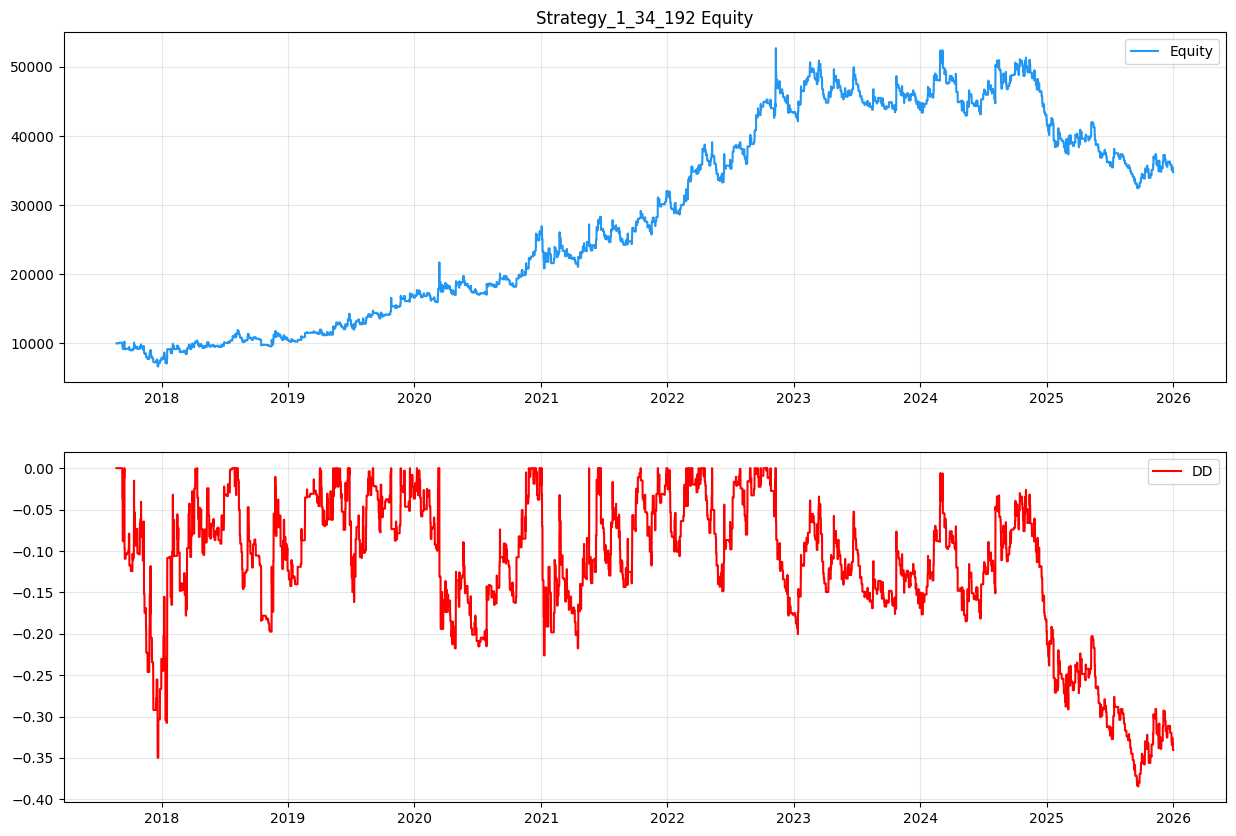

In [2]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNH CHIẾN LƯỢC (Strategy_1_34_192)
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',
    'START_DATE': '01/01/2015',
    'END_DATE': '31/12/2025',
    'INITIAL_CAPITAL': 10000.0,

    # --- Indicators Parameters ---
    'KC_PERIOD': 20,
    'KC_MULT_SETUP': 2.0,    # Độ lệch chuẩn để kích hoạt tín hiệu (Open > KC 2.0)
    'RSI_PERIOD': 14,

    'HH_LL_PERIOD': 10,      # Chu kỳ tìm Highest/Lowest Close
    'SHIFT_LOOKBACK': 3,     # Lùi lại 3 nến để tính giá đặt lệnh (Quan trọng)

    'ATR_ENTRY_PERIOD': 23,  # ATR tính Buffer vào lệnh
    'ATR_SL_PERIOD': 20,     # ATR tính SL
    'ATR_PT_PERIOD': 25,     # ATR tính PT
    'ATR_TRAIL_PERIOD': 150, # ATR tính Trailing (Theo logic Java hash)

    # --- Entry & Management ---
    'ENTRY_MULT': 2.4,       # Hệ số nhân với ATR(23) để cộng vào Entry
    'SL_COEF': 2.2,          # 2.2 * ATR(20)
    'PT_COEF': 4.3,          # 4.3 * ATR(25)
    'TRAIL_COEF': 3.0,       # 3.0 * ATR(150)

    'ORDER_EXPIRATION': 5,   # Hủy lệnh sau 5 nến
    'TIME_EXIT_BARS': 14,    # Thoát sau 14 nến

    # Costs
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0002
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    print(f"📡 Checking connection to Binance...")
    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451:
            print("⚠️ US IP detected. Switching to Binance.US...")
            base_url = "https://api.binance.us"
            if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
    except:
        print("⚠️ Connection failed. Retrying with Binance.US...")
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    url = base_url + "/api/v3/klines"
    start_time = str_to_millis(start_str)

    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {req_symbol} ({interval}) from {base_url}...")

    while start_time < end_time:
        params = {"symbol": req_symbol, "interval": interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200: break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            if len(all_klines) % 5000 == 0:
                print(f"   -> Downloaded: {len(all_klines)} candles")
            time.sleep(0.05)
        except: break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    print(f"✅ Download Complete! Total: {len(df)} candles.")
    return df

# ==============================================================================
# BƯỚC 4: BACKTEST ENGINE (Logic Strategy_1_34_192)
# ==============================================================================
def run_strategy(df):
    print("⚙️ Calculating indicators & Running Strategy_1_34_192...")
    df = df.copy()
    c = CONFIG

    # --- A. INDICATORS ---
    # 1. Keltner Channels (20, 2.0) - Dùng để Setup
    # StrategyQuant mặc định dùng SMA cho Basis của Keltner
    kc_basis = ta.sma(df['Close'], length=c['KC_PERIOD'])
    kc_range = ta.atr(df['High'], df['Low'], df['Close'], length=c['KC_PERIOD'])
    df['KC_Upper'] = kc_basis + (c['KC_MULT_SETUP'] * kc_range)
    df['KC_Lower'] = kc_basis - (c['KC_MULT_SETUP'] * kc_range)

    # 2. RSI (14)
    df['RSI'] = ta.rsi(df['Close'], length=c['RSI_PERIOD'])

    # 3. ATRs cho quản lý vốn & Entry Buffer
    df['ATR_Entry'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_ENTRY_PERIOD'])
    df['ATR_SL']    = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_SL_PERIOD'])
    df['ATR_PT']    = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_PT_PERIOD'])
    df['ATR_Trail'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_TRAIL_PERIOD'])

    # 4. Highest/Lowest Close (Price Channel) - Dữ liệu quá khứ để đặt lệnh
    # Shift 3: Tính toán dựa trên dữ liệu lùi lại 3 nến (Theo code Java: shift=3)
    df['Highest_Close'] = df['Close'].shift(c['SHIFT_LOOKBACK']).rolling(c['HH_LL_PERIOD']).max()
    df['Lowest_Close']  = df['Close'].shift(c['SHIFT_LOOKBACK']).rolling(c['HH_LL_PERIOD']).min()

    # ATR Entry cũng phải shift 3 để đồng bộ với công thức
    df['ATR_Entry_Shifted'] = df['ATR_Entry'].shift(c['SHIFT_LOOKBACK'])

    df.dropna(inplace=True)

    # --- B. INITIALIZATION ---
    capital = c['INITIAL_CAPITAL']
    position = 0; entry_price = 0.0; entry_idx = 0
    sl_price = 0.0; tp_price = 0.0
    pending_orders = []; trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Numpy Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index

    # Indicators Array
    kc_upper = df['KC_Upper'].values; kc_lower = df['KC_Lower'].values
    rsi = df['RSI'].values

    highest_close = df['Highest_Close'].values; lowest_close = df['Lowest_Close'].values
    atr_entry_shifted = df['ATR_Entry_Shifted'].values

    atr_sl = df['ATR_SL'].values; atr_pt = df['ATR_PT'].values; atr_trail = df['ATR_Trail'].values

    # --- C. MAIN LOOP ---
    for i in range(1, len(df)):

        # 1. QUẢN LÝ LỆNH ĐANG CHẠY (EXIT)
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]

            if position == 1:
                if lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif highs[i] >= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            elif position == -1:
                if highs[i] >= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif lows[i] <= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            if exit_signal:
                # Tính PnL
                if position == 1:
                    real_exit = min(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 - c['SLIPPAGE'])
                    pnl = (real_exit - entry_price) / entry_price
                else:
                    real_exit = max(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 + c['SLIPPAGE'])
                    pnl = (entry_price - real_exit) / entry_price

                net_pnl = pnl - (c['FEE_RATE'] * 2)
                capital += (capital * net_pnl)

                trades.append({'Date': times[i], 'Type': 'Long' if position == 1 else 'Short', 'Reason': exit_reason, 'PnL': capital * net_pnl, 'Equity': capital})
                position = 0; pending_orders = []

            else:
                # Trailing Stop (ATR 150)
                trail_dist = c['TRAIL_COEF'] * atr_trail[i]
                if position == 1:
                    new_sl = closes[i] - trail_dist
                    if new_sl > sl_price: sl_price = new_sl
                elif position == -1:
                    new_sl = closes[i] + trail_dist
                    if new_sl < sl_price: sl_price = new_sl

        # 2. XỬ LÝ LỆNH CHỜ (ENTRY)
        if position == 0:
            # Lọc lệnh hết hạn (5 nến)
            pending_orders = [o for o in pending_orders if (i - o['created_idx']) < c['ORDER_EXPIRATION']]

            triggered = None
            for order in pending_orders:
                if order['type'] == 'buy' and highs[i] >= order['price']:
                    triggered = order; exec_price = max(opens[i], order['price']) if opens[i] > order['price'] else order['price']
                    break
                elif order['type'] == 'sell' and lows[i] <= order['price']:
                    triggered = order; exec_price = min(opens[i], order['price']) if opens[i] < order['price'] else order['price']
                    break

            if triggered:
                entry_idx = i
                if triggered['type'] == 'buy':
                    position = 1
                    entry_price = exec_price * (1 + c['SLIPPAGE'])
                    sl_price = exec_price - (c['SL_COEF'] * atr_sl[i])
                    tp_price = exec_price + (c['PT_COEF'] * atr_pt[i])
                else:
                    position = -1
                    entry_price = exec_price * (1 - c['SLIPPAGE'])
                    sl_price = exec_price + (c['SL_COEF'] * atr_sl[i])
                    tp_price = exec_price - (c['PT_COEF'] * atr_pt[i])

                pending_orders = []

        # 3. TẠO TÍN HIỆU MỚI (Logic Strategy_1_34_192)
        if position == 0:
            # Lưu ý: Code Java so sánh Open hiện tại với KC quá khứ.
            # Trong backtest vector, opens[i] là giá mở cửa nến hiện tại. kc_upper[i-1] là giá trị KC đã chốt của nến trước.
            # Logic RSI: RSI(3 bars ago) < RSI(2 bars ago) => rsi[i-3] < rsi[i-2] (RSI đang tăng)

            rsi_rising = rsi[i-3] < rsi[i-2]
            rsi_falling = rsi[i-3] > rsi[i-2]

            # Setup Long: Open > KC Upper (2.0) & RSI Rising
            setup_long = (opens[i] > kc_upper[i-1]) and rsi_rising

            # Setup Short: Open < KC Lower (2.0) & RSI Falling
            setup_short = (opens[i] < kc_lower[i-1]) and rsi_falling

            # Entry Price Calculation (Shift 3)
            # Highest Close (10, shift 3) + 2.4 * ATR (23, shift 3)
            buy_pending_price = highest_close[i] + (c['ENTRY_MULT'] * atr_entry_shifted[i])
            sell_pending_price = lowest_close[i] - (c['ENTRY_MULT'] * atr_entry_shifted[i])

            if setup_long:
                pending_orders.append({'type': 'buy', 'price': buy_pending_price, 'created_idx': i})

            if setup_short and not setup_long:
                pending_orders.append({'type': 'sell', 'price': sell_pending_price, 'created_idx': i})

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: RUN & REPORT
# ==============================================================================
if __name__ == "__main__":
    df = fetch_binance_kline_df(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])

    if not df.empty:
        equity, trades_df = run_strategy(df)

        if not trades_df.empty:
            final_equity = equity.iloc[-1]
            total_return = (final_equity - CONFIG['INITIAL_CAPITAL']) / CONFIG['INITIAL_CAPITAL']

            rolling_max = equity.cummax()
            dd = (equity - rolling_max) / rolling_max
            max_dd = dd.min()

            wins = trades_df[trades_df['PnL'] > 0]
            losses = trades_df[trades_df['PnL'] <= 0]
            winrate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0

            gross_profit = wins['PnL'].sum(); gross_loss = abs(losses['PnL'].sum())
            profit_factor = gross_profit / gross_loss if gross_loss != 0 else 0

            days = (equity.index[-1] - equity.index[0]).days
            cagr = ((final_equity / CONFIG['INITIAL_CAPITAL']) ** (365.0 / days)) - 1 if days > 0 else 0

            returns = equity.pct_change().dropna()
            sharpe_ratio = (returns.mean() / returns.std()) * np.sqrt(365 * 24) if returns.std() != 0 else 0

            print(f"\n{'='*30}")
            print(f"📊 BACKTEST: Strategy_1_34_192 ({CONFIG['SYMBOL']})")
            print(f"{'='*30}")
            print(f"{'Final Equity:':>15} {final_equity:,.2f}")
            print(f"{'Total Return:':>15} {total_return:.2%}")
            print(f"{'CAGR (approx):':>15} {cagr:.2%}")
            print(f"{'Max Drawdown:':>15} {max_dd:.2%}")
            print(f"{'Sharpe Ratio:':>15} {sharpe_ratio:.2f}")
            print(f"{'Trades:':>15} {len(trades_df)}")
            print(f"{'Winrate:':>15} {winrate:.2%}")
            print(f"{'Profit Factor:':>15} {profit_factor:.2f}")
            print(f"{'='*30}")

            plt.figure(figsize=(15, 10))
            plt.subplot(2, 1, 1)
            plt.plot(equity, label='Equity', color='#2196F3'); plt.grid(True, alpha=0.3); plt.legend()
            plt.title('Strategy_1_34_192 Equity')
            plt.subplot(2, 1, 2)
            plt.plot(dd, label='DD', color='red'); plt.grid(True, alpha=0.3); plt.legend()
            plt.show()
        else:
            print("⚠️ No trades executed.")
    else:
        print("❌ No data.")